# Subscriptions by age
Number of subscribers and subscription rate for each age in the telecom campaign data.

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt

# The CSV wraps every row in an extra pair of quotes, so unwrap each line before parsing
with open("TeleCom_Data-1.csv", encoding="utf-8") as f:
    lines = [l.strip()[1:-1].replace('""', '"') for l in f if l.strip()]
df = pd.read_csv(io.StringIO("\n".join(lines)), sep=";")

df["subscribed"] = (df["y"] == "yes").astype(int)
print(df.shape, "| overall subscription rate:", round(df["subscribed"].mean(), 3))

(41180, 22) | overall subscription rate: 0.113


In [2]:
# One row per age: number of subscribers, number of customers, and the rate
by_age = df.groupby("age")["subscribed"].agg(subscribers="sum", customers="count")
by_age["rate"] = by_age["subscribers"] / by_age["customers"]
by_age.head()

,subscribers,customers,rate
age,,,
17,2,5,0.400000
18,12,28,0.428571
19,20,42,0.476190
20,23,65,0.353846
21,29,102,0.284314


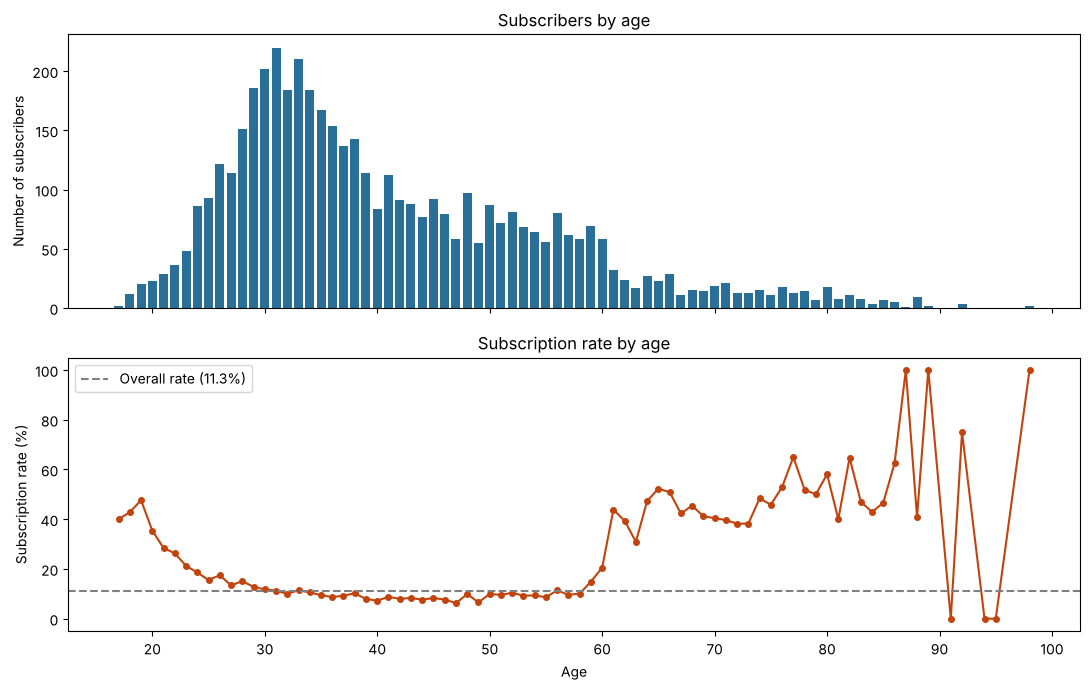

In [3]:
overall = df["subscribed"].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1]})

# Top: how many customers subscribed at each age
ax1.bar(by_age.index, by_age["subscribers"], color="#2a6f97")
ax1.set_ylabel("Number of subscribers")
ax1.set_title("Subscribers by age")

# Bottom: share of customers at that age who subscribed
ax2.plot(by_age.index, by_age["rate"] * 100, marker="o", ms=4, color="#c1440e")
ax2.axhline(overall * 100, ls="--", color="grey", label=f"Overall rate ({overall:.1%})")
ax2.set_ylabel("Subscription rate (%)")
ax2.set_xlabel("Age")
ax2.set_title("Subscription rate by age")
ax2.legend()

plt.tight_layout()
plt.show()

**Reading the chart.** The top panel mostly reflects how many customers exist at each age, so most subscribers are in their 30s. The bottom panel removes that effect: the rate is lowest between about 30 and 58, and rises at both ends, especially after age 60. Rates above about age 85 rest on very few customers and are noisy.